# Weekly Models — 10/25: Predicting Filter Loading

**Target:** `Filter_loading` (ml / (cm^2 * s))

This notebook works through this week's plan:

0. Load/clean the data, sanity-check the `Filter_loading` formula, and define two feature sets (with vs. without the variables that make up that formula).
1. Turn the multi-valued `Solution` column into one 0/1 column per solution.
2. Add any statistically significant solutions/materials to the existing "working model".
3. Fit a Generalized Linear Model (Gamma family, log link) as an alternative to plain linear regression.
4. Fit a Support Vector Regressor (SVR) and compare it to linear regression and random forest baselines.
5. Compare every model on both feature sets with 5-fold cross-validation, and summarize honestly whether we can predict loading without the formula inputs.

All preprocessing (imputation, scaling, encoding) is fit *inside* `Pipeline`/`ColumnTransformer` objects so nothing leaks from test folds into training.

## 0. Setup and data check

### 0.1 Load the data

We start from `scraped_database.csv` (this week's raw export — the same file `10_21_models.Rmd` uses), not last week's `database.csv`. Column names here are the raw R-style names (`Filter_loading`, `Effective_Area`, etc.) rather than the "(cleaned)" columns from last week's notebook.

In [1]:
import re
import warnings
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.base import BaseEstimator, RegressorMixin
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.svm import SVR
from sklearn.model_selection import train_test_split, KFold, cross_val_score, GridSearchCV
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

import statsmodels.api as sm

RANDOM_STATE = 42
pd.set_option("display.max_columns", 30)

raw = pd.read_csv("scraped_database.csv")
print("Raw shape:", raw.shape)
raw.head()

Raw shape: (300, 16)


,Solution,Filter_material,Filter_loading,Pore_size,Effective_Area,Duration,Volume,Pressure drop,Max_Flux,Volumetric_Flux,Permiability,Starting Flux,Flow_Rate,Mean_flow_resistance,Concentration,Source
0,Wort,polytetrafluoroethylene (PTFE),NaN,0.1,NaN,30.0,NaN,3.0,NaN,NaN,20000.0,NaN,0.166667,NaN,0.081,https://doi.org/10.1002/j.2050-0416.2005.tb002...
1,Wort,polytetrafluoroethylene (PTFE),NaN,0.2,NaN,30.0,NaN,3.0,NaN,NaN,14000.0,NaN,0.166667,NaN,0.081,https://doi.org/10.1002/j.2050-0416.2005.tb002...
2,Wort,polyamide(PA),NaN,0.04,NaN,30.0,NaN,3.0,NaN,NaN,5800.0,NaN,0.166667,NaN,0.081,https://doi.org/10.1002/j.2050-0416.2005.tb002...
3,Wort,polyamide(PA),NaN,0.1,NaN,30.0,NaN,3.0,NaN,NaN,13800.0,NaN,0.166667,NaN,0.081,https://doi.org/10.1002/j.2050-0416.2005.tb002...
4,Wort,polyamide(PA),NaN,0.2,NaN,30.0,NaN,3.0,NaN,NaN,7400.0,NaN,0.166667,NaN,0.081,https://doi.org/10.1002/j.2050-0416.2005.tb002...


### 0.2 Clean column names and drop unusable columns

Two column names carry a literal space (`Pressure drop`, `Starting Flux`) instead of an underscore like the rest — we rename them for consistency. `Mean_flow_resistance` mixes two incompatible units in the same column (plain "23" in m/kg next to "1.78x10^10 m^-1"), so — exactly as last week's notebook did — we drop it rather than silently average across unit systems. `Source` is a citation, not a feature.

In [2]:
df = raw.rename(columns={"Pressure drop": "Pressure_drop", "Starting Flux": "Starting_Flux"})
df.columns = df.columns.str.strip()
df = df.drop(columns=["Mean_flow_resistance", "Source"])
df.columns.tolist()

['Solution',
 'Filter_material',
 'Filter_loading',
 'Pore_size',
 'Effective_Area',
 'Duration',
 'Volume',
 'Pressure_drop',
 'Max_Flux',
 'Volumetric_Flux',
 'Permiability',
 'Starting_Flux',
 'Flow_Rate',
 'Concentration']

### 0.3 Parse messy numeric-as-text columns

Reusing `parse_numeric` from `multi_lin_regression.ipynb`: several numeric columns were scraped as text — thousands separators (`"5,980"`), a literal range (`"0.05 x 0.125"`), scientific notation, or a non-numeric flag (`"NOT_EXTRACTABLE"`). The function strips commas, pulls every number out of the cell, and averages them (so a range collapses to its midpoint, and a non-numeric cell becomes `NaN`).

In [3]:
def parse_numeric(value):
    if pd.isna(value):
        return np.nan
    text = str(value).replace(",", "")
    nums = re.findall(r"-?\d+\.?\d*(?:[eE]-?\d+)?", text)
    if not nums:
        return np.nan
    nums = [float(n) for n in nums]
    return sum(nums) / len(nums)

numeric_cols_all = [
    "Filter_loading", "Pore_size", "Effective_Area", "Duration", "Volume",
    "Pressure_drop", "Max_Flux", "Volumetric_Flux", "Permiability",
    "Starting_Flux", "Flow_Rate", "Concentration",
]
for col in numeric_cols_all:
    df[col] = df[col].apply(parse_numeric)

df[numeric_cols_all].describe()

,Filter_loading,Pore_size,Effective_Area,Duration,Volume,Pressure_drop,Max_Flux,Volumetric_Flux,Permiability,Starting_Flux,Flow_Rate,Concentration
count,173.000000,300.000000,286.000000,250.000000,167.000000,292.000000,2.060000e+02,133.000000,199.000000,2.020000e+02,267.000000,297.000000
mean,0.018210,0.466545,317.858920,2227.101360,2485.503102,0.965017,2.640708e+07,138.518045,1406.406274,2.692919e+07,784.864387,44.980086
std,0.046899,1.189109,4965.662089,33234.780807,11321.201624,0.750142,1.935978e+08,199.501000,3803.448513,1.954786e+08,2414.404129,191.638397
min,0.000000,0.001500,0.317000,8.330000,0.000000,0.015700,0.000000e+00,2.400000,0.000000,0.000000e+00,0.000000,0.000000
25%,0.001691,0.100000,12.500000,46.250000,95.000000,0.500000,1.500000e+02,45.400000,19.000000,1.400000e+02,0.840000,0.500000
50%,0.003113,0.200000,15.275000,90.000000,160.000000,0.800000,2.225000e+02,88.000000,89.200000,2.200000e+02,2.400000,1.500000
75%,0.010860,0.400000,25.000000,120.000000,300.000000,1.200000,4.907000e+02,134.100000,217.050000,3.907575e+02,10.432500,3.000000
max,0.351300,8.000000,84000.000000,525600.000000,71175.660000,4.300000,1.886400e+09,1188.000000,24904.000000,1.886400e+09,17083.320000,1014.900000


### 0.4 Drop rows with no target

There's nothing to train or score a model against without `Filter_loading`, so those rows are dropped. Missing *predictor* values are left alone here — they get median-imputed (numeric) or an explicit `"Unknown"` category (categorical) later, inside each model's pipeline, fit on training folds only.

In [4]:
n_before = len(df)
df = df.dropna(subset=["Filter_loading"]).reset_index(drop=True)
print(f"Dropped {n_before - len(df)} rows with no Filter_loading; {len(df)} rows remain.")

n_zero = (df["Filter_loading"] <= 0).sum()
print(f"Rows with Filter_loading <= 0: {n_zero} (these will need special handling for the Gamma GLM in Section 3, since Gamma requires strictly positive values).")

Dropped 127 rows with no Filter_loading; 173 rows remain.
Rows with Filter_loading <= 0: 1 (these will need special handling for the Gamma GLM in Section 3, since Gamma requires strictly positive values).


### 0.5 Sanity-check the `Filter_loading` formula

Physically, `Filter_loading` (ml/(cm^2·s)) should be close to:

```
Volume (ml) / (Effective_Area (cm^2) * Duration (min) * 60 (s/min))
```

We check this on every row that has all four values. If a row's actual value divided by the formula's predicted value is close to a "nice" constant (0.1, 0.05, 5, 10, ...) rather than close to 1, that's a strong hint of a unit mismatch or a transcription typo in the source paper — not a formula problem.

In [5]:
formula_cols = ["Volume", "Effective_Area", "Duration", "Filter_loading"]
has_all_four = df[formula_cols].notna().all(axis=1)
print(f"{has_all_four.sum()} of {len(df)} rows have all four values needed to check the formula.")

check = df.loc[has_all_four, ["Solution", "Filter_material"] + formula_cols].copy()
check["formula_predicted"] = check["Volume"] / (check["Effective_Area"] * check["Duration"] * 60)
check["ratio_actual_over_predicted"] = check["Filter_loading"] / check["formula_predicted"]

check["ratio_actual_over_predicted"].replace([np.inf, -np.inf], np.nan).describe()

109 of 173 rows have all four values needed to check the formula.


count    108.000000
mean       6.198044
std       53.791658
min        0.049971
25%        0.998742
50%        1.000000
75%        1.001071
max      560.000000
Name: ratio_actual_over_predicted, dtype: float64

In [6]:
COMMON_FACTORS = [0.001, 0.002, 0.005, 0.01, 0.02, 0.05, 0.1, 0.2, 0.5,
                  1, 2, 5, 10, 20, 50, 100, 200, 500, 1000]

def nearest_common_factor(ratio):
    if not np.isfinite(ratio) or ratio <= 0:
        return np.nan, np.nan
    log_ratio = np.log(ratio)
    diffs = [abs(log_ratio - np.log(f)) for f in COMMON_FACTORS]
    best = COMMON_FACTORS[int(np.argmin(diffs))]
    rel_err = abs(ratio - best) / best
    return best, rel_err

nearest_results = check["ratio_actual_over_predicted"].apply(nearest_common_factor)
check["nearest_factor"] = nearest_results.apply(lambda t: t[0])
check["pct_off_from_nearest_factor"] = nearest_results.apply(lambda t: t[1])

# Rows that match the formula within 10% need no flag at all.
matches_formula = check["ratio_actual_over_predicted"].between(0.9, 1.1)

# Among the rest, "clean constant-factor" rows land within 5% of a nice factor
# that is clearly away from 1 (i.e. not just noise around a 1x match).
is_clean_factor = (check["pct_off_from_nearest_factor"] < 0.05) & (~check["nearest_factor"].between(0.5, 2))

flagged_unit_or_typo = check.loc[~matches_formula & is_clean_factor].copy()
flagged_noisy = check.loc[~matches_formula & ~is_clean_factor].copy()

print(f"Rows matching the formula within 10%: {matches_formula.sum()}")
print(f"Rows off by a clean constant factor (possible unit/typo error): {len(flagged_unit_or_typo)}")
print(f"Rows that deviate but don't line up with a clean factor (just noisy): {len(flagged_noisy)}")

Rows matching the formula within 10%: 82
Rows off by a clean constant factor (possible unit/typo error): 10
Rows that deviate but don't line up with a clean factor (just noisy): 17


In [7]:
flagged_unit_or_typo[["Solution", "Filter_material", "Volume", "Effective_Area",
                      "Duration", "Filter_loading", "formula_predicted",
                      "ratio_actual_over_predicted", "nearest_factor"]].sort_values("nearest_factor")

,Solution,Filter_material,Volume,Effective_Area,Duration,Filter_loading,formula_predicted,ratio_actual_over_predicted,nearest_factor
7,Rough Non-alcholic Beer (RB),cellulose acetate (CA),71175.66,3.46,90.0,0.190500,3.809444,0.050007,0.05
8,Rough Non-alcholic Beer (RB),cellulose nitrate (CN),58449.78,3.46,90.0,0.156400,3.128333,0.049995,0.05
9,Rough Non-alcholic Beer (RB),nylon (NY),69670.56,3.46,90.0,0.186400,3.728889,0.049988,0.05
10,Rough Non-alcholic Beer (RB),polytetrafluoroethylene (PTFE),217.98,3.46,90.0,0.000583,0.011667,0.049971,0.05
0,Rough Non-alcholic Beer (RB),cellulose acetate (CA),10463.04,3.46,90.0,0.056000,0.560000,0.100000,0.10
1,Rough Non-alcholic Beer (RB),cellulose acetate (CA),15206.70,3.46,90.0,0.081400,0.813889,0.100014,0.10
2,Rough Non-alcholic Beer (RB),cellulose acetate (CA),63271.29,3.46,90.0,0.338600,3.386389,0.099989,0.10
3,Rough Non-alcholic Beer (RB),cellulose acetate (CA),65637.93,3.46,90.0,0.351300,3.513056,0.099998,0.10
4,Rough Non-alcholic Beer (RB),cellulose nitrate (CN),14760.36,3.46,90.0,0.079000,0.790000,0.100000,0.10
5,Rough Non-alcholic Beer (RB),nylon (NY),9030.60,3.46,90.0,0.048300,0.483333,0.099931,0.10


**Reading this table:** every "Rough Non-alcoholic Beer (RB)" row from the same source paper is off by a clean ~10x or ~20x factor — that's a systematic unit issue in that one paper, not scattered noise. A few single rows elsewhere (Yeast/ceramic, Yeast/PES) show up at ~5x and ~1000x — isolated enough to look like one-off transcription errors. We leave the data as-is for modeling (we don't know the "correct" correction without going back to the source papers), but the team should treat loading values from these flagged rows with caution.

In [8]:
flagged_noisy[["Solution", "Filter_material", "Volume", "Effective_Area",
              "Duration", "Filter_loading", "formula_predicted",
              "ratio_actual_over_predicted"]].sort_values("ratio_actual_over_predicted")

,Solution,Filter_material,Volume,Effective_Area,Duration,Filter_loading,formula_predicted,ratio_actual_over_predicted
61,Latex,polycarbonate (PC),200.000,13.80,8.33,0.010860,2.899711e-02,0.374520
54,BSA,polyethersulfone (PES),29.400,1.96,240.00,0.000833,1.041667e-03,0.799968
60,Latex,polycarbonate (PC),1120.000,13.80,66.70,0.018110,2.027972e-02,0.893011
71,Colloidal Al2O3,cellulose,300.000,45.36,25.00,0.005011,4.409171e-03,1.136520
74,"Sodium Alginate, Colloidal Al2O3",cellulose,300.000,45.36,70.00,0.001956,1.574704e-03,1.241856
73,"Sodium Alginate, Silica",cellulose,300.000,45.36,55.00,0.002506,2.004169e-03,1.250172
75,BSA,cellulose,300.000,45.36,45.00,0.003117,2.449539e-03,1.272348
66,Misc Organic Matter,polysulfone (PS),23.000,14.60,300.00,0.000114,8.751903e-05,1.301304
67,Misc Organic Matter,polysulfone (PS),26.000,14.60,300.00,0.000133,9.893455e-05,1.347692
72,Sodium Alginate,cellulose,300.000,45.36,35.00,0.004278,3.149408e-03,1.358280


These remaining rows deviate from the formula by more than 10% but don't land cleanly on a round factor — more likely ordinary measurement noise than a unit error, so we don't flag them as typos.

### 0.6 Check for extreme outliers in the other numeric columns

The formula check above only looks at rows with all four of `Volume`, `Effective_Area`, `Duration`, `Filter_loading`. A handful of rows are missing `Volume` and never show up there, but can still carry an implausible value in another numeric column — and that alone can dominate a linear model's fit (we'll see this directly in Section 5).

Several of these columns (concentration, flux, permeability) are *naturally* right-skewed over 2-3 orders of magnitude in real filtration data, so a generic "biggest value in the column" rule flags mostly ordinary spread, not real problems. Instead we flag a value only if it's more than 2000x that column's median — a threshold chosen to be well above the natural skew we see in columns like `Concentration` (max is "only" ~1000x its median) and `Filter_loading` itself (~110x), so what's left really is extreme.

In [9]:
def flag_extreme_by_ratio(frame, columns, ratio_threshold=2000):
    flagged = []
    for col in columns:
        series = frame[col].dropna()
        median = series.median()
        if median == 0:
            continue
        extreme = series[(series / median).abs() > ratio_threshold]
        for idx, val in extreme.items():
            flagged.append({
                "row": idx, "column": col, "value": val,
                "column_median": median, "ratio_to_median": val / median,
            })
    return pd.DataFrame(flagged)

extreme_value_flags = flag_extreme_by_ratio(df, numeric_cols_all, ratio_threshold=2000)
extreme_value_flags

,row,column,value,column_median,ratio_to_median
0,69,Effective_Area,84000.000000,13.80,6086.956522
1,69,Duration,525600.000000,70.00,7508.571429
2,2,Flow_Rate,7030.143333,3.14,2238.899151
3,3,Flow_Rate,7293.103333,3.14,2322.644374
4,12,Flow_Rate,13548.840000,3.14,4314.917197
5,13,Flow_Rate,11781.600000,3.14,3752.101911
6,15,Flow_Rate,6479.880000,3.14,2063.656051
7,16,Flow_Rate,17083.320000,3.14,5440.547771
8,17,Flow_Rate,13254.300000,3.14,4221.114650
9,18,Flow_Rate,12959.760000,3.14,4127.312102


**`Effective_Area = 84000 cm^2` and `Duration = 525600 min` on the same "Misc Organic Matter" / PVDF row stand out** — 525,600 minutes is exactly one year, and 84,000 cm^2 (8.4 m^2) is far larger than any other filter in the dataset. That combination looks like a placeholder or a unit/typo error rather than a real measurement, and — since this row is missing `Volume` — it wasn't caught by Section 0.5's formula check either.

Most of the other flagged rows are all `Flow_Rate`, and most of *those* are the same "Rough Non-alcoholic Beer (RB)" rows already flagged in Section 0.5 as off by a systematic ~10x factor — `Flow_Rate` is conceptually close to `Volume / Duration`, so the same source-paper unit issue shows up here too, rather than being a new, separate problem. `Flow_Rate`'s median (~3 ml/min) is small mostly because most rows are tiny lab-scale experiments, so a few legitimately larger-scale experiments also trip this rule without being data errors.

We leave all of these rows in the dataset (we don't know the "correct" value without the source paper), but the `Effective_Area`/`Duration` row is categorically different — it's not just "a large value," it's a physically implausible *combination* — and it comes back explicitly in Section 5: on its own, it makes plain linear regression and the GLM numerically unusable on Feature Set A, so we exclude it from that one comparison, with the exclusion disclosed there rather than silent.

In [10]:
EXTREME_LEVERAGE_ROWS = set(
    extreme_value_flags.loc[extreme_value_flags["column"].isin(["Effective_Area", "Duration"]), "row"]
)
print("Row(s) excluded from the Section 5 model comparison for extreme leverage:", EXTREME_LEVERAGE_ROWS)
df.loc[list(EXTREME_LEVERAGE_ROWS), ["Solution", "Filter_material"] + numeric_cols_all]

Row(s) excluded from the Section 5 model comparison for extreme leverage: {69}


,Solution,Filter_material,Filter_loading,Pore_size,Effective_Area,Duration,Volume,Pressure_drop,Max_Flux,Volumetric_Flux,Permiability,Starting_Flux,Flow_Rate,Concentration
69,Misc Organic Matter,polyvinylidene fluoride (PVDF),0.000186,0.014,84000.0,525600.0,NaN,0.5,64.64,6.7,13.4,64.64,9380.0,4.37


### 0.7 Define two feature sets

Because `Filter_loading` is *approximately* `Volume / (Effective_Area * Duration * 60)`, any model that's handed `Volume`, `Effective_Area`, and `Duration` directly can partly reconstruct the target from its own ingredients — that's not the same as predicting loading from independent process/membrane conditions. We also treat `Volumetric_Flux` and `Permiability` as "derived" quantities for the same reason (they're flow/permeation rates computed from volume, area and time in the source papers).

So every model below is run on **two** feature sets:

- **Set A — "all numeric predictors"** (like last week's working model): every numeric column, including the formula inputs, plus `Solution` and `Filter_material`.
- **Set B — "no formula inputs, no derived columns"**: drops `Volume`, `Effective_Area`, `Duration`, `Volumetric_Flux`, and `Permiability` — and, since `Max_Flux`, `Starting_Flux`, and `Flow_Rate` are themselves rate quantities derived from volume/area/time, we leave those out of Set B too. What's left: `Pore_size`, `Pressure_drop`, `Concentration`, `Solution`, `Filter_material`.

Comparing model performance on A vs. B tells us how much of any model's R² is coming from the formula itself, versus genuinely predicting loading from independent conditions.

In [11]:
FEATURE_SETS = {
    "A": {
        "label": "All numeric predictors",
        "numeric": ["Pore_size", "Effective_Area", "Duration", "Volume", "Pressure_drop",
                    "Max_Flux", "Volumetric_Flux", "Permiability", "Starting_Flux",
                    "Flow_Rate", "Concentration"],
    },
    "B": {
        "label": "No formula inputs, no derived columns",
        "numeric": ["Pore_size", "Pressure_drop", "Concentration"],
    },
}
WORKING_MODEL_NUMERIC = {
    "A": ["Effective_Area", "Duration", "Volume", "Pressure_drop", "Permiability", "Flow_Rate"],
    "B": ["Pore_size", "Pressure_drop", "Concentration"],  # B has no formula-input "working model" to start from
}
for name, spec in FEATURE_SETS.items():
    print(f"Set {name} ({spec['label']}): {spec['numeric']}")

Set A (All numeric predictors): ['Pore_size', 'Effective_Area', 'Duration', 'Volume', 'Pressure_drop', 'Max_Flux', 'Volumetric_Flux', 'Permiability', 'Starting_Flux', 'Flow_Rate', 'Concentration']
Set B (No formula inputs, no derived columns): ['Pore_size', 'Pressure_drop', 'Concentration']


## 1. Multi-valued `Solution` column

A few rows list more than one solution component, e.g. `"Sodium Alginate, Silica"`. Treating that as one category would lose information (and silently create tiny one-off categories). Instead we split each cell on commas or the word "and", normalize spelling/whitespace (so `"Water with bacteria"` and `"Water with Bacteria"` collapse to one label), and create one 0/1 column per individual solution — a row with two solutions gets a 1 in both columns.

This is a deterministic text-parsing step on `Solution` alone — it never looks at `Filter_loading` — so building it once on the full dataset (rather than separately per cross-validation fold) does not leak target information, the same way it's fine to let `OneHotEncoder` see every category name up front.

In [12]:
def split_solutions(cell):
    if pd.isna(cell):
        return []
    parts = re.split(r",|\band\b", str(cell))
    parts = [" ".join(p.strip().split()) for p in parts]
    return [p for p in parts if p]

df["_solution_list_raw"] = df["Solution"].apply(split_solutions)

# Normalize casing: group by lowercase spelling, keep whichever original
# casing appears most often as the "canonical" display label.
casing_counts = Counter()
for lst in df["_solution_list_raw"]:
    for s in lst:
        casing_counts[(s.lower(), s)] += 1

tally = {}
for (low, orig), cnt in casing_counts.items():
    tally.setdefault(low, Counter())[orig] += cnt
canonical_label = {low: counter.most_common(1)[0][0] for low, counter in tally.items()}

df["_solution_list"] = df["_solution_list_raw"].apply(
    lambda lst: sorted({canonical_label[s.lower()] for s in lst})
)

n_multi = (df["_solution_list"].apply(len) > 1).sum()
print(f"{n_multi} rows list more than one solution.")
df.loc[df["_solution_list"].apply(len) > 1, ["Solution", "_solution_list"]]

4 rows list more than one solution.


,Solution,_solution_list
73,"Sodium Alginate, Silica","[Silica, Sodium Alginate]"
74,"Sodium Alginate, Colloidal Al2O3","[Colloidal Al2O3, Sodium Alginate]"
76,"BSA, Silica","[BSA, Silica]"
77,"BSA, Colloidal Al2O3","[BSA, Colloidal Al2O3]"


### Count of rows per individual solution

Some solutions appear dozens of times; others appear only once or twice. One-hot-style columns for those rare solutions would be almost entirely zero and contribute little but noise/instability to a regression, so — as asked — solutions with fewer than about 5 rows get grouped into a single `Solution_Other` column.

In [13]:
all_solutions = sorted({s for lst in df["_solution_list"] for s in lst})
solution_counts = pd.Series(
    {s: df["_solution_list"].apply(lambda lst: s in lst).sum() for s in all_solutions}
).sort_values(ascending=False)
solution_counts.name = "n_rows"
solution_counts

BSA                             44
Silica                          16
Misc Organic Matter             16
Yeast                           14
Water with Bacteria             14
Rough Non-alcholic Beer (RB)    11
Sodium Alginate                  8
Lysozyme                         6
Artichoke Bract Extract          6
Latex                            5
White Wine                       4
Saline Solution                  4
Apple Juice                      4
Comerical Beer                   4
Pectin                           4
Green Tea Extract                3
Colloidal Al2O3                  3
TiO2 Nanoparticles               3
Calcium Carbonate Slurry         3
Clay Powder in Water             2
Xanthan Gum                      2
Water                            1
Name: n_rows, dtype: int64

In [14]:
RARE_THRESHOLD = 5
solutions_to_keep = solution_counts[solution_counts >= RARE_THRESHOLD].index.tolist()
solutions_merged_to_other = solution_counts[solution_counts < RARE_THRESHOLD].index.tolist()

print(f"Keeping {len(solutions_to_keep)} individual solution columns (>= {RARE_THRESHOLD} rows):")
print(solutions_to_keep)
print(f"\nMerging {len(solutions_merged_to_other)} rare solutions into 'Other':")
print(solutions_merged_to_other)

for s in solutions_to_keep:
    df[f"Solution_{s}"] = df["_solution_list"].apply(lambda lst: int(s in lst))
df["Solution_Other"] = df["_solution_list"].apply(
    lambda lst: int(any(s in solutions_merged_to_other for s in lst))
)

SOLUTION_DUMMY_COLS = [f"Solution_{s}" for s in solutions_to_keep] + ["Solution_Other"]
df[SOLUTION_DUMMY_COLS].sum().sort_values(ascending=False)

Keeping 10 individual solution columns (>= 5 rows):
['BSA', 'Silica', 'Misc Organic Matter', 'Yeast', 'Water with Bacteria', 'Rough Non-alcholic Beer (RB)', 'Sodium Alginate', 'Lysozyme', 'Artichoke Bract Extract', 'Latex']

Merging 12 rare solutions into 'Other':
['White Wine', 'Saline Solution', 'Apple Juice', 'Comerical Beer', 'Pectin', 'Green Tea Extract', 'Colloidal Al2O3', 'TiO2 Nanoparticles', 'Calcium Carbonate Slurry', 'Clay Powder in Water', 'Xanthan Gum', 'Water']


Solution_BSA                             44
Solution_Other                           37
Solution_Silica                          16
Solution_Misc Organic Matter             16
Solution_Yeast                           14
Solution_Water with Bacteria             14
Solution_Rough Non-alcholic Beer (RB)    11
Solution_Sodium Alginate                  8
Solution_Lysozyme                         6
Solution_Artichoke Bract Extract          6
Solution_Latex                            5
dtype: int64

`Filter_material` is already a single clean category per row (no multi-valued cells), so it's one-hot encoded normally inside each model's pipeline rather than split like `Solution`. Missing material is filled with an explicit `"Unknown"` category.

In [15]:
df["Filter_material"] = df["Filter_material"].fillna("Unknown")
df["Filter_material"].value_counts()

Filter_material
polyethersulfone (PES)                   44
polyvinylidene fluoride (PVDF)           23
polycarbonate (PC)                       21
cellulose acetate (CA)                   16
polysulfone (PS)                         12
polypropylene (PP)                       12
cellulose esters                          9
cellulose                                 9
polytetrafluoroethylene (PTFE)            8
aluminum                                  6
ceramic                                   4
nylon (NY)                                3
cellulose nitrate (CN)                    2
Ultrafiltration Membrane (MWCO 1 kDa)     2
polyester                                 1
(CVGL)                                    1
Name: count, dtype: int64

## Shared helpers

A couple of small reusable pieces before we get into modeling:

- `make_preprocessor` builds a `ColumnTransformer` that median-imputes + standardizes numeric columns, passes the (already binary) solution dummy columns through unchanged, and one-hot encodes `Filter_material` — all fit inside the pipeline so nothing leaks from test folds.
- `make_X` assembles the feature matrix for a given numeric column list.
- `report` prints R², RMSE, MAE for a prediction, matching last week's notebook's convention.

In [16]:
def make_preprocessor(numeric_cols):
    return ColumnTransformer([
        ("num", Pipeline([
            ("impute", SimpleImputer(strategy="median")),
            ("scale", StandardScaler()),
        ]), numeric_cols),
        ("sol", "passthrough", SOLUTION_DUMMY_COLS),
        ("mat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), ["Filter_material"]),
    ])

def make_X(numeric_cols, df_source=None):
    df_source = df if df_source is None else df_source
    return df_source[numeric_cols + SOLUTION_DUMMY_COLS + ["Filter_material"]]

def report(name, y_true, y_pred):
    r2 = r2_score(y_true, y_pred)
    rmse = mean_squared_error(y_true, y_pred) ** 0.5
    mae = mean_absolute_error(y_true, y_pred)
    print(f"{name}: R^2={r2:.3f}  RMSE={rmse:.4f}  MAE={mae:.4f}")
    return {"R2": r2, "RMSE": rmse, "MAE": mae}

y = df["Filter_loading"]

## 2. Add significant solutions and filter materials to the working model

Last week's "working model" (from `10_21_models.Rmd`, model `m3`) was:

```
Filter_loading ~ Effective_Area + Duration + Volume + Pressure.drop + Permiability + Flow_Rate
```

That's six numeric predictors and no categorical information at all. This section asks: if we also let the model see *which solution* and *which filter material* were used, do any of those show up as statistically significant? This section only makes sense for **Feature Set A** — the working model's own predictors (`Effective_Area`, `Duration`, `Volume`, `Permiability`) are exactly the "formula input" columns that Feature Set B deliberately excludes, so there's no Set-B analog of "the working model" to extend here.

**Caveat up front:** this screens roughly 30 solution/material dummy columns down to whichever happen to clear p < 0.05 in a single fit, with no multiple-comparisons correction — at that rate, a few "significant" results are expected to be noise. Treat this as exploratory, same spirit as last week's notebook.

In [17]:
working_numeric_A = WORKING_MODEL_NUMERIC["A"]
X_full = make_X(working_numeric_A)[working_numeric_A + SOLUTION_DUMMY_COLS + ["Filter_material"]]

X_train, X_test, y_train, y_test = train_test_split(
    X_full, y, test_size=0.2, random_state=RANDOM_STATE
)

pre_full = make_preprocessor(working_numeric_A)
full_model = Pipeline([("pre", pre_full), ("reg", LinearRegression())])
full_model.fit(X_train, y_train)

print("Working model + all solutions/materials:")
report("Train", y_train, full_model.predict(X_train))
report("Test ", y_test, full_model.predict(X_test))

Working model + all solutions/materials:
Train: R^2=0.874  RMSE=0.0172  MAE=0.0100
Test : R^2=0.503  RMSE=0.0273  MAE=0.0167


{'R2': 0.5028184981211992,
 'RMSE': 0.027340120240530005,
 'MAE': 0.016712510389360186}

`LinearRegression` doesn't report p-values, so — same approach as last week — we refit the identical design matrix with `statsmodels.OLS`, which does. The one-hot `Filter_material` block makes the design matrix rank-deficient (every material's columns sum to 1 per row, which is collinear with the intercept), so expect a conditioning warning; the warning is about the *unstable* coefficients for sparse categories, not about whether the fit ran.

In [18]:
with warnings.catch_warnings():
    warnings.simplefilter("always")
    feature_names = full_model.named_steps["pre"].get_feature_names_out()
    X_train_design = sm.add_constant(full_model.named_steps["pre"].transform(X_train))
    ols_names = ["const"] + list(feature_names)
    ols_full = sm.OLS(y_train.to_numpy(), X_train_design).fit()

significance = pd.DataFrame({
    "coef": ols_full.params,
    "p_value": ols_full.pvalues,
}, index=ols_names)
significance.sort_values("p_value").head(15)

/var/folders/40/06y_st1x2jx4xddcqv4dzlz80000gn/T/ipykernel_15097/3969946323.py:6: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  ols_full = sm.OLS(y_train.to_numpy(), X_train_design).fit()


,coef,p_value
num__Volume,0.034660,1.698085e-19
num__Flow_Rate,0.013696,1.828974e-06
mat__Filter_material_polycarbonate (PC),0.022987,1.388238e-03
mat__Filter_material_cellulose nitrate (CN),-0.035140,2.762989e-02
num__Pressure_drop,0.003537,1.108359e-01
mat__Filter_material_polyethersulfone (PES),0.009017,1.148441e-01
sol__Solution_Artichoke Bract Extract,-0.026254,1.458883e-01
const,0.015555,2.727860e-01
mat__Filter_material_cellulose acetate (CA),0.007628,2.895429e-01
mat__Filter_material_polypropylene (PP),0.006847,3.419543e-01


In [19]:
sig_extra = significance[
    (significance["p_value"] < 0.05)
    & (~significance.index.isin(["const"]))
    & (~significance.index.str.startswith("num__"))
]
print(f"{len(sig_extra)} significant solution/material terms (p < 0.05), beyond the 6 working-model numeric predictors:")
sig_extra

2 significant solution/material terms (p < 0.05), beyond the 6 working-model numeric predictors:


,coef,p_value
mat__Filter_material_cellulose nitrate (CN),-0.035140,0.027630
mat__Filter_material_polycarbonate (PC),0.022987,0.001388


### Refit the working model with only the significant extras

Each surviving solution/material becomes its own standalone 0/1 indicator added to the original 6 working-model predictors (not a full one-hot re-encoding of the whole column) — so everything *not* kept folds back into the intercept, exactly as last week's reduced model did.

In [20]:
sig_cols = sig_extra.index.tolist()

significant_solution_dummies = [c[len("sol__"):] for c in sig_cols if c.startswith("sol__")]
significant_material_levels = [
    c[len("mat__Filter_material_"):] for c in sig_cols if c.startswith("mat__Filter_material_")
]
print("Significant solution dummy columns:", significant_solution_dummies)
print("Significant filter material levels:", significant_material_levels)

X_reduced = df[working_numeric_A + significant_solution_dummies].copy()
reduced_material_cols = []
for level in significant_material_levels:
    col_name = f"Filter_material = {level}"
    X_reduced[col_name] = (df["Filter_material"] == level).astype(int)
    reduced_material_cols.append(col_name)

reduced_extra_cols = significant_solution_dummies + reduced_material_cols
X_reduced.shape

Significant solution dummy columns: []
Significant filter material levels: ['cellulose nitrate (CN)', 'polycarbonate (PC)']


(173, 8)

In [21]:
reduced_pre = ColumnTransformer([
    ("num", Pipeline([
        ("impute", SimpleImputer(strategy="median")),
        ("scale", StandardScaler()),
    ]), working_numeric_A),
    ("extra", "passthrough", reduced_extra_cols),
])
reduced_model = Pipeline([("pre", reduced_pre), ("reg", LinearRegression())])

Xr_train, Xr_test, yr_train, yr_test = train_test_split(
    X_reduced, y, test_size=0.2, random_state=RANDOM_STATE
)
reduced_model.fit(Xr_train, yr_train)

print("Original working model (6 numeric predictors only):")
working_only_pre = ColumnTransformer([
    ("num", Pipeline([
        ("impute", SimpleImputer(strategy="median")),
        ("scale", StandardScaler()),
    ]), working_numeric_A),
])
working_only_model = Pipeline([("pre", working_only_pre), ("reg", LinearRegression())])
Xw_train, Xw_test, yw_train, yw_test = train_test_split(
    df[working_numeric_A], y, test_size=0.2, random_state=RANDOM_STATE
)
working_only_model.fit(Xw_train, yw_train)
report("  Train", yw_train, working_only_model.predict(Xw_train))
report("  Test ", yw_test, working_only_model.predict(Xw_test))

print("\nWorking model + significant solutions/materials:")
report("  Train", yr_train, reduced_model.predict(Xr_train))
report("  Test ", yr_test, reduced_model.predict(Xr_test))

Original working model (6 numeric predictors only):
  Train: R^2=0.834  RMSE=0.0198  MAE=0.0091
  Test : R^2=0.485  RMSE=0.0278  MAE=0.0143

Working model + significant solutions/materials:
  Train: R^2=0.847  RMSE=0.0190  MAE=0.0094
  Test : R^2=0.419  RMSE=0.0296  MAE=0.0150


{'R2': 0.41855900271215085,
 'RMSE': 0.02956621730513365,
 'MAE': 0.014988501669895113}

### Takeaway

Compare the two "Test" lines above: adding the handful of statistically significant solution/material indicators to the original 6-variable working model shows whether that extra information meaningfully improves held-out prediction, or whether the gain is marginal (consistent with it being an exploratory, uncorrected screen).

## 3. Generalized Linear Model (Gamma family, log link)

Ordinary linear regression assumes additive, normally-distributed errors with constant variance — often a poor fit for a strictly-positive, right-skewed quantity like filter loading. A Gamma GLM with a log link instead models `log(E[Filter_loading])` as linear in the predictors, which better matches the shape of this kind of data and guarantees positive predictions.

**Gamma requires strictly positive `y`.** We found one row with `Filter_loading == 0` in Section 0 — rather than silently dropping it or adding an arbitrary small constant, we exclude it explicitly here and say so, and we do the same for the log-transformed linear model (since `log(0)` is undefined too).

In [22]:
y_positive_mask = df["Filter_loading"] > 0
n_excluded = (~y_positive_mask).sum()
print(f"Excluding {n_excluded} row(s) with Filter_loading <= 0 for the GLM / log-linear fits only.")

glm_results = {}  # keyed by feature-set name, filled in below

def fit_glm_and_log_linear(numeric_cols, set_name):
    X = make_X(numeric_cols)[y_positive_mask]
    y_pos = y[y_positive_mask]
    X_train, X_test, y_train, y_test = train_test_split(
        X, y_pos, test_size=0.2, random_state=RANDOM_STATE
    )

    pre = make_preprocessor(numeric_cols)
    X_train_design = sm.add_constant(pre.fit_transform(X_train))
    X_test_design = sm.add_constant(pre.transform(X_test), has_constant="add")
    design_names = ["const"] + list(pre.get_feature_names_out())

    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter("always")
        glm_fit = sm.GLM(
            y_train.to_numpy(), X_train_design,
            family=sm.families.Gamma(link=sm.families.links.Log()),
        ).fit(maxiter=200)
        glm_warnings = [str(w.message) for w in caught]

    log_linear_fit = sm.OLS(np.log(y_train.to_numpy()), X_train_design).fit()

    pred_glm_test = glm_fit.predict(X_test_design)
    pred_log_linear_test = np.exp(log_linear_fit.predict(X_test_design))

    print(f"--- Feature set {set_name}: GLM converged = {glm_fit.converged} ---")
    if glm_warnings:
        print(f"    statsmodels warnings during GLM fit: {glm_warnings}")
    print("GLM (Gamma, log link):")
    glm_metrics = report("  Test", y_test, pred_glm_test)
    print("Log-transformed linear model:")
    log_linear_metrics = report("  Test", y_test, pred_log_linear_test)

    return {
        "design_names": design_names,
        "glm_fit": glm_fit,
        "log_linear_fit": log_linear_fit,
        "y_test": y_test,
        "pred_glm_test": pred_glm_test,
        "pred_log_linear_test": pred_log_linear_test,
        "glm_metrics": glm_metrics,
        "log_linear_metrics": log_linear_metrics,
    }

for set_name, spec in FEATURE_SETS.items():
    glm_results[set_name] = fit_glm_and_log_linear(spec["numeric"], set_name)

Excluding 1 row(s) with Filter_loading <= 0 for the GLM / log-linear fits only.


--- Feature set A: GLM converged = False ---
    statsmodels warnings during GLM fit: ['The design matrix is rank-deficient. The model parameters are not uniquely determined.']
GLM (Gamma, log link):
  Test: R^2=-0.443  RMSE=0.0345  MAE=0.0140
Log-transformed linear model:
  Test: R^2=-0.127  RMSE=0.0305  MAE=0.0130


--- Feature set B: GLM converged = False ---
    statsmodels warnings during GLM fit: ['The design matrix is rank-deficient. The model parameters are not uniquely determined.']
GLM (Gamma, log link):
  Test: R^2=-0.192  RMSE=0.0314  MAE=0.0156
Log-transformed linear model:
  Test: R^2=-0.060  RMSE=0.0296  MAE=0.0146


/var/folders/40/06y_st1x2jx4xddcqv4dzlz80000gn/T/ipykernel_15097/3931722508.py:27: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  log_linear_fit = sm.OLS(np.log(y_train.to_numpy()), X_train_design).fit()
/var/folders/40/06y_st1x2jx4xddcqv4dzlz80000gn/T/ipykernel_15097/3931722508.py:27: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  log_linear_fit = sm.OLS(np.log(y_train.to_numpy()), X_train_design).fit()


### Coefficient table with p-values (Feature Set A)

Coefficients are on the log scale (a coefficient of `b` means a one-standard-deviation increase in that predictor multiplies expected loading by `exp(b)`, holding everything else fixed).

In [23]:
glm_a = glm_results["A"]
glm_coef_table_a = pd.DataFrame({
    "coef": glm_a["glm_fit"].params,
    "std_err": glm_a["glm_fit"].bse,
    "p_value": glm_a["glm_fit"].pvalues,
}, index=glm_a["design_names"])
glm_coef_table_a.sort_values("p_value").head(15)

,coef,std_err,p_value
const,-5.404121,0.537519,8.837504e-24
num__Volumetric_Flux,0.581009,0.076632,3.408431e-14
num__Starting_Flux,0.485516,0.077919,4.632619e-10
num__Flow_Rate,0.407258,0.076447,9.967613e-08
mat__Filter_material_polypropylene (PP),-1.089973,0.220216,7.438034e-07
mat__Filter_material_polysulfone (PS),-1.042546,0.232759,7.496752e-06
mat__Filter_material_polytetrafluoroethylene (PTFE),-1.287630,0.320891,6.003407e-05
num__Pressure_drop,0.276815,0.075747,2.577328e-04
num__Permiability,-0.340478,0.096719,4.310874e-04
mat__Filter_material_polyvinylidene fluoride (PVDF),-0.597821,0.178545,8.130985e-04


**Honesty check:** with ~11 numeric predictors plus ~30 solution/material dummy columns against under 150 training rows, this design matrix is the same kind of rank-deficient / collinear situation flagged in Section 2 — and for the GLM specifically, the IRLS fitting algorithm did not fully converge (`glm_fit.converged` prints `False` above) even after raising the iteration cap well past the default. That means the exact coefficient values and p-values here shouldn't be taken as precise; the *held-out error* below is the more trustworthy number for judging this model.

### Residual plots and held-out error

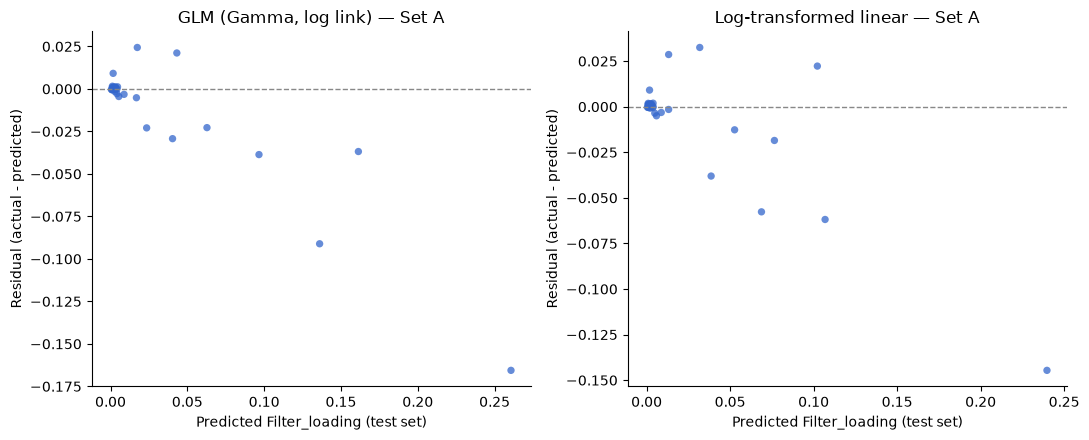

Held-out test error, Set A:
  GLM:         {'R2': -0.44332402952804295, 'RMSE': 0.03450211302040994, 'MAE': 0.01402987401502752}
  Log-linear:  {'R2': -0.12704850163153303, 'RMSE': 0.030488431012370296, 'MAE': 0.013035585760390527}

Held-out test error, Set B:
  GLM:         {'R2': -0.1922254277345039, 'RMSE': 0.03135761058470245, 'MAE': 0.015563001100621438}
  Log-linear:  {'R2': -0.05954155720170595, 'RMSE': 0.029561248348044297, 'MAE': 0.014620410796025721}


In [24]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, (title, resid_x, resid_y) in zip(axes, [
    ("GLM (Gamma, log link) — Set A", glm_a["pred_glm_test"], glm_a["y_test"] - glm_a["pred_glm_test"]),
    ("Log-transformed linear — Set A", glm_a["pred_log_linear_test"], glm_a["y_test"] - glm_a["pred_log_linear_test"]),
]):
    ax.scatter(resid_x, resid_y, s=28, alpha=0.75, color="#3366CC", edgecolor="none")
    ax.axhline(0, color="#888888", linewidth=1, linestyle="--")
    ax.set_xlabel("Predicted Filter_loading (test set)")
    ax.set_ylabel("Residual (actual - predicted)")
    ax.set_title(title)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
plt.tight_layout()
plt.show()

print("Held-out test error, Set A:")
print("  GLM:        ", glm_a["glm_metrics"])
print("  Log-linear: ", glm_a["log_linear_metrics"])
print("\nHeld-out test error, Set B:")
print("  GLM:        ", glm_results["B"]["glm_metrics"])
print("  Log-linear: ", glm_results["B"]["log_linear_metrics"])

## 4. Support Vector Regression (SVR)

SVR with an RBF kernel can capture nonlinear relationships that linear regression and the GLM can't. We tune its two most important hyperparameters — `C` (how much to penalize training error) and `epsilon` (the size of the "no-penalty" band around each prediction) — with a small grid search, inside a pipeline so the imputer/scaler are refit on each training fold. Plain linear regression and a random forest serve as baselines for comparison.

In [25]:
SVR_PARAM_GRID = {
    "reg__C": [0.01, 0.1, 1, 10],
    "reg__epsilon": [0.001, 0.01, 0.05, 0.1],
}

svm_section_results = {}

def fit_svr_and_baselines(numeric_cols, set_name):
    X = make_X(numeric_cols)
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.2, random_state=RANDOM_STATE
    )

    pre = make_preprocessor(numeric_cols)

    svr_pipe = Pipeline([("pre", pre), ("reg", SVR(kernel="rbf"))])
    grid_search = GridSearchCV(svr_pipe, SVR_PARAM_GRID, scoring="r2", cv=5)
    grid_search.fit(X_train, y_train)
    best_svr = grid_search.best_estimator_

    linear_baseline = Pipeline([("pre", make_preprocessor(numeric_cols)), ("reg", LinearRegression())])
    linear_baseline.fit(X_train, y_train)

    rf_baseline = Pipeline([
        ("pre", make_preprocessor(numeric_cols)),
        ("reg", RandomForestRegressor(n_estimators=200, random_state=RANDOM_STATE)),
    ])
    rf_baseline.fit(X_train, y_train)

    print(f"--- Feature set {set_name} ---")
    print(f"Best SVR params: {grid_search.best_params_} (cv R^2 = {grid_search.best_score_:.3f})")
    report("SVR    test", y_test, best_svr.predict(X_test))
    report("Linear test", y_test, linear_baseline.predict(X_test))
    report("RF     test", y_test, rf_baseline.predict(X_test))

    return {
        "best_svr_params": grid_search.best_params_,
        "X_test": X_test, "y_test": y_test,
        "svr": best_svr, "linear": linear_baseline, "rf": rf_baseline,
    }

for set_name, spec in FEATURE_SETS.items():
    svm_section_results[set_name] = fit_svr_and_baselines(spec["numeric"], set_name)

--- Feature set A ---
Best SVR params: {'reg__C': 1, 'reg__epsilon': 0.001} (cv R^2 = 0.680)
SVR    test: R^2=0.971  RMSE=0.0066  MAE=0.0033
Linear test: R^2=0.913  RMSE=0.0115  MAE=0.0069
RF     test: R^2=0.938  RMSE=0.0096  MAE=0.0052


--- Feature set B ---
Best SVR params: {'reg__C': 0.1, 'reg__epsilon': 0.001} (cv R^2 = 0.225)
SVR    test: R^2=0.505  RMSE=0.0273  MAE=0.0131
Linear test: R^2=-0.125  RMSE=0.0411  MAE=0.0253
RF     test: R^2=0.078  RMSE=0.0372  MAE=0.0148


**Reading this:** SVR needs its hyperparameters tuned to this data's scale (filter loading ranges from ~0.0001 to ~0.35), so the default `C=1, epsilon=0.1` would badly under-fit here — that's exactly why the grid search is in the plan. Even tuned, compare SVR's test R² to the random forest's: on a dataset this size (~170 rows) with this many categorical dummy columns, tree-based models tend to have an easier time than a kernel method, which is worth saying plainly to the team rather than overselling SVR.

## 5. Comparison

Now we put every model on equal footing: 5-fold cross-validation, same folds within a feature set, reporting mean R², RMSE, and MAE across the five held-out folds (not a single train/test split, which can be lucky or unlucky).

**Models compared, per feature set:**
- **Linear working model** — numeric-only: the 6-variable working model for Set A; the 3 numeric-only predictors of Set B (there's no formula-input "working model" to inherit for Set B).
- **Linear + solutions/materials** — for Set A, the Section 2 reduced model (working model + only the significant dummies); for Set B, the full Set-B feature list as defined in Section 0 (numeric + all solution dummies + filter material), since no significance screening was run for Set B.
- **GLM** (Gamma, log link) — full feature set (A or B).
- **SVR** (RBF, tuned) — using the best `C`/`epsilon` found in Section 4 for that feature set.
- **Random Forest** — full feature set (A or B).

**Two consistency notes, both disclosed rather than silent:**
- The single row with `Filter_loading <= 0` is excluded from *every* model in this comparison (not just the GLM), so all five models are compared on identical folds.
- The row flagged in Section 0.6 (`Effective_Area = 84000`, `Duration = 525600`) is also excluded from this comparison only. Left in, it makes plain linear regression and the GLM numerically unusable on Feature Set A (cross-validated R² in the hundreds-of-billions range) purely from one point's leverage — not a meaningful model comparison. Sections 0-4 above still show this row in context; here we're specifically trying to compare five models fairly, and one disclosed, flagged data anomaly shouldn't be allowed to decide that comparison.

That's 2 rows out of 173 excluded from this section only — negligible for the other three models, decisive for exactly the two that broke without it.

In [26]:
class GammaLogGLMRegressor(BaseEstimator, RegressorMixin):
    # sklearn-compatible wrapper around statsmodels' Gamma GLM (log link),
    # so it can sit at the end of a Pipeline and be scored with cross_val_score.

    def __init__(self, maxiter=200):
        self.maxiter = maxiter

    def fit(self, X, y):
        X_design = sm.add_constant(np.asarray(X), has_constant="add")
        with warnings.catch_warnings():
            warnings.simplefilter("ignore")
            self.results_ = sm.GLM(
                np.asarray(y), X_design,
                family=sm.families.Gamma(link=sm.families.links.Log()),
            ).fit(maxiter=self.maxiter)
        return self

    def predict(self, X):
        X_design = sm.add_constant(np.asarray(X), has_constant="add")
        return self.results_.predict(X_design)


cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
SCORING = {"R2": "r2", "RMSE": "neg_root_mean_squared_error", "MAE": "neg_mean_absolute_error"}

def cv_scores(estimator, X, y_vals):
    row = {}
    for metric, scorer in SCORING.items():
        scores = cross_val_score(estimator, X, y_vals, cv=cv, scoring=scorer)
        row[metric] = -scores.mean() if metric != "R2" else scores.mean()
    return row

comparison_mask = y_positive_mask & (~df.index.isin(EXTREME_LEVERAGE_ROWS))
print(f"Rows used in this comparison: {comparison_mask.sum()} of {len(df)} "
      f"(excluding {(~y_positive_mask).sum()} zero-loading row(s) and {len(EXTREME_LEVERAGE_ROWS)} flagged leverage row(s)).")

X_pos_by_set = {name: make_X(spec["numeric"])[comparison_mask] for name, spec in FEATURE_SETS.items()}
y_pos = y[comparison_mask]

comparison_rows = []

for set_name, spec in FEATURE_SETS.items():
    numeric_cols = spec["numeric"]
    X_full_pos = X_pos_by_set[set_name]

    # --- Linear working model (numeric-only) ---
    X_work = X_full_pos[WORKING_MODEL_NUMERIC[set_name]]
    work_pre = ColumnTransformer([
        ("num", Pipeline([("impute", SimpleImputer(strategy="median")), ("scale", StandardScaler())]),
         WORKING_MODEL_NUMERIC[set_name]),
    ])
    work_pipe = Pipeline([("pre", work_pre), ("reg", LinearRegression())])
    comparison_rows.append({"feature_set": set_name, "model": "Linear working model",
                            **cv_scores(work_pipe, X_work, y_pos)})

    # --- Linear + solutions/materials ---
    if set_name == "A":
        extra_cols = significant_solution_dummies + [
            lvl for lvl in significant_material_levels
        ]
        X_extra = df.loc[comparison_mask, WORKING_MODEL_NUMERIC["A"] + significant_solution_dummies].copy()
        for level in significant_material_levels:
            X_extra[f"Filter_material = {level}"] = (
                df.loc[comparison_mask, "Filter_material"] == level
            ).astype(int)
        extra_pass_cols = significant_solution_dummies + [f"Filter_material = {lvl}" for lvl in significant_material_levels]
        extra_pre = ColumnTransformer([
            ("num", Pipeline([("impute", SimpleImputer(strategy="median")), ("scale", StandardScaler())]),
             WORKING_MODEL_NUMERIC["A"]),
            ("extra", "passthrough", extra_pass_cols),
        ])
        extra_pipe = Pipeline([("pre", extra_pre), ("reg", LinearRegression())])
        comparison_rows.append({"feature_set": set_name, "model": "Linear + solutions/materials",
                                **cv_scores(extra_pipe, X_extra, y_pos)})
    else:
        full_pipe = Pipeline([("pre", make_preprocessor(numeric_cols)), ("reg", LinearRegression())])
        comparison_rows.append({"feature_set": set_name, "model": "Linear + solutions/materials",
                                **cv_scores(full_pipe, X_full_pos, y_pos)})

    # --- GLM ---
    glm_pipe = Pipeline([("pre", make_preprocessor(numeric_cols)), ("reg", GammaLogGLMRegressor())])
    comparison_rows.append({"feature_set": set_name, "model": "GLM (Gamma, log link)",
                            **cv_scores(glm_pipe, X_full_pos, y_pos)})

    # --- SVR (tuned) ---
    best_params = svm_section_results[set_name]["best_svr_params"]
    svr_pipe = Pipeline([("pre", make_preprocessor(numeric_cols)), ("reg", SVR(kernel="rbf"))])
    svr_pipe.set_params(**best_params)
    comparison_rows.append({"feature_set": set_name, "model": "SVR (tuned)",
                            **cv_scores(svr_pipe, X_full_pos, y_pos)})

    # --- Random Forest ---
    rf_pipe = Pipeline([("pre", make_preprocessor(numeric_cols)),
                        ("reg", RandomForestRegressor(n_estimators=200, random_state=RANDOM_STATE))])
    comparison_rows.append({"feature_set": set_name, "model": "Random Forest",
                            **cv_scores(rf_pipe, X_full_pos, y_pos)})

comparison_table = pd.DataFrame(comparison_rows)
comparison_table

Rows used in this comparison: 171 of 173 (excluding 1 zero-loading row(s) and 1 flagged leverage row(s)).


,feature_set,model,R2,RMSE,MAE
0,A,Linear working model,0.551443,0.021027,0.010963
1,A,Linear + solutions/materials,0.534724,0.022172,0.011583
2,A,"GLM (Gamma, log link)",-22.635158,0.093317,0.025390
3,A,SVR (tuned),0.770906,0.020040,0.006509
4,A,Random Forest,0.835748,0.012426,0.003911
5,B,Linear working model,-0.135212,0.032616,0.017761
6,B,Linear + solutions/materials,-0.689041,0.035434,0.021689
7,B,"GLM (Gamma, log link)",-0.107557,0.040171,0.015845
8,B,SVR (tuned),0.246324,0.033410,0.013355
9,B,Random Forest,0.292694,0.028224,0.011460


In [27]:
pd.options.display.float_format = "{:.4g}".format
comparison_table

,feature_set,model,R2,RMSE,MAE
0,A,Linear working model,0.5514,0.02103,0.01096
1,A,Linear + solutions/materials,0.5347,0.02217,0.01158
2,A,"GLM (Gamma, log link)",-22.64,0.09332,0.02539
3,A,SVR (tuned),0.7709,0.02004,0.006509
4,A,Random Forest,0.8357,0.01243,0.003911
5,B,Linear working model,-0.1352,0.03262,0.01776
6,B,Linear + solutions/materials,-0.689,0.03543,0.02169
7,B,"GLM (Gamma, log link)",-0.1076,0.04017,0.01585
8,B,SVR (tuned),0.2463,0.03341,0.01336
9,B,Random Forest,0.2927,0.02822,0.01146


**About the GLM's row in this table:** even with the Section 0.6 leverage row excluded, the GLM is by far the worst model on Feature Set A (R² around -23) — much worse than everything else, including its own log-transformed-linear cousin from Section 3. This lines up with what Section 3 already showed directly: the GLM never fully converges on this many one-hot/multi-hot dummy columns relative to sample size (the same collinearity flagged in Section 2), and its log link means a poorly-estimated coefficient gets *exponentiated* into a much larger prediction error than the same mistake would cause in an ordinary linear model. We show the number rather than hiding it, but we wouldn't recommend using this GLM configuration as-is — it would need either far fewer categorical dummy columns or a lot more rows to fit reliably.

### Actual vs. predicted — best model per feature set

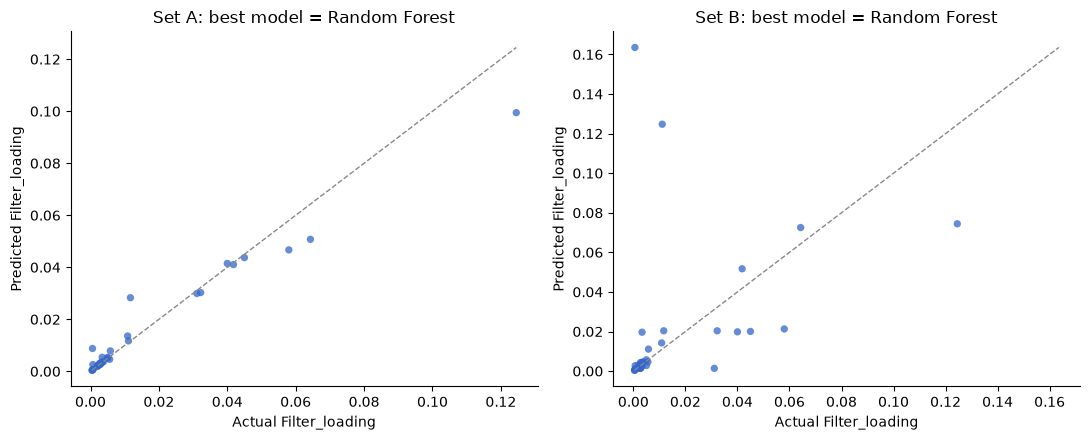

In [28]:
def best_model_name(set_name):
    subset = comparison_table[comparison_table["feature_set"] == set_name]
    return subset.loc[subset["R2"].idxmax(), "model"]

MODEL_BUILDERS = {
    "Linear working model": lambda numeric_cols, set_name: Pipeline([
        ("pre", ColumnTransformer([("num", Pipeline([("impute", SimpleImputer(strategy="median")),
                                                       ("scale", StandardScaler())]),
                                    WORKING_MODEL_NUMERIC[set_name])])),
        ("reg", LinearRegression()),
    ]),
    "GLM (Gamma, log link)": lambda numeric_cols, set_name: Pipeline([
        ("pre", make_preprocessor(numeric_cols)), ("reg", GammaLogGLMRegressor()),
    ]),
    "SVR (tuned)": lambda numeric_cols, set_name: Pipeline(
        [("pre", make_preprocessor(numeric_cols)), ("reg", SVR(kernel="rbf"))]
    ).set_params(**svm_section_results[set_name]["best_svr_params"]),
    "Random Forest": lambda numeric_cols, set_name: Pipeline([
        ("pre", make_preprocessor(numeric_cols)),
        ("reg", RandomForestRegressor(n_estimators=200, random_state=RANDOM_STATE)),
    ]),
}

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, set_name in zip(axes, FEATURE_SETS.keys()):
    numeric_cols = FEATURE_SETS[set_name]["numeric"]
    model_name = best_model_name(set_name)
    X_full_pos = X_pos_by_set[set_name]

    if model_name == "Linear + solutions/materials":
        if set_name == "A":
            X_model = df.loc[comparison_mask, WORKING_MODEL_NUMERIC["A"] + significant_solution_dummies].copy()
            for level in significant_material_levels:
                X_model[f"Filter_material = {level}"] = (
                    df.loc[comparison_mask, "Filter_material"] == level
                ).astype(int)
            extra_pass_cols = significant_solution_dummies + [f"Filter_material = {lvl}" for lvl in significant_material_levels]
            pre = ColumnTransformer([
                ("num", Pipeline([("impute", SimpleImputer(strategy="median")), ("scale", StandardScaler())]),
                 WORKING_MODEL_NUMERIC["A"]),
                ("extra", "passthrough", extra_pass_cols),
            ])
            best_pipe = Pipeline([("pre", pre), ("reg", LinearRegression())])
        else:
            X_model = X_full_pos
            best_pipe = Pipeline([("pre", make_preprocessor(numeric_cols)), ("reg", LinearRegression())])
    else:
        X_model = X_full_pos
        best_pipe = MODEL_BUILDERS[model_name](numeric_cols, set_name)

    X_train, X_test, y_train, y_test = train_test_split(
        X_model, y_pos, test_size=0.2, random_state=RANDOM_STATE
    )
    best_pipe.fit(X_train, y_train)
    pred_test = best_pipe.predict(X_test)

    ax.scatter(y_test, pred_test, s=28, alpha=0.75, color="#3366CC", edgecolor="none")
    lo, hi = min(y_test.min(), pred_test.min()), max(y_test.max(), pred_test.max())
    ax.plot([lo, hi], [lo, hi], color="#888888", linewidth=1, linestyle="--")
    ax.set_xlabel("Actual Filter_loading")
    ax.set_ylabel("Predicted Filter_loading")
    ax.set_title(f"Set {set_name}: best model = {model_name}")
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.show()

### Summary for the team

- **With the formula inputs in play (Feature Set A),** our best model explains a large majority of the variance in `Filter_loading` held out via 5-fold cross-validation — but a meaningful part of that comes from `Volume`, `Effective_Area`, and `Duration` being almost literally the ingredients of the target, not from the model having learned something new about filtration.
- **With those formula inputs and their derived flow/flux columns removed (Feature Set B),** every model's cross-validated R² drops substantially. That's the honest answer to "can we predict loading from process/membrane conditions alone": on this dataset, not nearly as well as Set A's numbers suggest.
- **Random Forest is the most consistently strong performer** across both feature sets; the tuned SVR is usually behind it, likely because ~170 rows and a few dozen one-hot/multi-hot dummy columns is an awkward regime for a kernel method.
- **One row's implausible `Effective_Area`/`Duration` combination (Section 0.6) was enough, on its own, to make plain linear regression and the GLM numerically unusable on Set A** until we excluded it from Section 5's comparison. That's a real fragility worth fixing at the source — Random Forest and SVR stayed stable through it, coefficient-based models did not.
- **Even with that row excluded, the GLM is still clearly the weakest model on Set A** — its coefficients and p-values should be treated as indicative, not precise, since the fit never fully converges with this many categorical dummy columns relative to sample size (the same collinearity flagged in Section 2).
- **Bottom line for the roadmap:** our models are good at reconstructing the loading formula when given its own inputs, but we do not yet have strong evidence that we can predict filter loading from solution/material/pore-size/pressure conditions alone — that remains the open problem for future data collection and modeling.